**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación - CICESE  
Luis Felipe García Domínguez

# Tarea 5: CNN
## Dataset: MNIST

---

# 1. Preparación de datos y exploración inicial

Importamos las librerías necesarias, definimos colores y cargamos MNIST desde Keras.

In [ ]:
import os
import warnings

# Manejo de warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from sklearn.model_selection import train_test_split
from tensorflow import keras

# Oculta barras de progreso de Keras
keras.utils.disable_interactive_logging()

# Colores para gráficas
AZUL_OSCURO = "#112057"
AZUL_MEDIO = "#3C51A9"
AZUL = "#7697CD"
NARANJA = "#E76A28"
VERDE = "#2E8B57"
GRIS = "#5B6584"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlecolor": AZUL_OSCURO,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": AZUL_OSCURO,
    "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E3E6EF",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "legend.frameon": False,
})

(x_des, y_des), (x_test, y_test) = keras.datasets.mnist.load_data()

Se compararán las arquitecturas en condiciones igualitarias. Del notebook de la clase reutilizamos:

- Las particiones estratificadas (`8000` imágenes de entrenamiento, `1500` de validación y `2000` de prueba)
- La semilla (`42`)
- El margen negro de 4 píxeles por lado.

Ese margen lleva cada imagen de `28 × 28` a `36 × 36` píxeles, de modo que más adelante podamos desplazar los dígitos hasta 4 píxeles en cualquier dirección sin recortar el trazo original.

In [2]:
SEMILLA = 42
N_ENT, N_VAL, N_PRUEBA = 8000, 1500, 2000
MARGEN = 4

i_ent, i_val = train_test_split(
    np.arange(len(y_des)),
    train_size=N_ENT,
    test_size=N_VAL,
    stratify=y_des,
    random_state=SEMILLA,
)
i_prueba, _ = train_test_split(
    np.arange(len(y_test)),
    train_size=N_PRUEBA,
    stratify=y_test,
    random_state=SEMILLA,
)


def preparar_imagenes(imagenes):
    """Agrega margen negro de 4 píxeles por lado, canal y normaliza a [0, 1]."""
    imagenes = np.pad(imagenes, ((0, 0), (MARGEN, MARGEN), (MARGEN, MARGEN)))
    return imagenes[..., None].astype(np.float32) / 255.0


X_ent, y_ent = preparar_imagenes(x_des[i_ent]), y_des[i_ent]
X_val, y_val = preparar_imagenes(x_des[i_val]), y_des[i_val]
X_prueba, y_prueba = preparar_imagenes(x_test[i_prueba]), y_test[i_prueba]
FORMA = X_ent.shape[1:]

for nombre, X in [("Entrenamiento", X_ent), ("Validación", X_val), ("Prueba", X_prueba)]:
    print(f"{nombre}: forma={X.shape}, dtype={X.dtype}, min={X.min():.1f}, max={X.max():.1f}")

Entrenamiento: forma=(8000, 36, 36, 1), dtype=float32, min=0.0, max=1.0
Validación: forma=(1500, 36, 36, 1), dtype=float32, min=0.0, max=1.0
Prueba: forma=(2000, 36, 36, 1), dtype=float32, min=0.0, max=1.0


Antes de entrenar modelos, verificamos que las diez clases (dígitos del 0 al 9) mantengan proporciones balanceadas en las tres particiones y visualizamos un ejemplo de cada dígito con el margen aplicado.

,Entrenamiento,Validación,Prueba
Dígito,,,
0,790,148,196
1,899,169,227
2,794,149,206
3,818,153,202
4,779,146,196
5,723,135,178
6,789,148,192
7,835,157,206
8,780,146,195


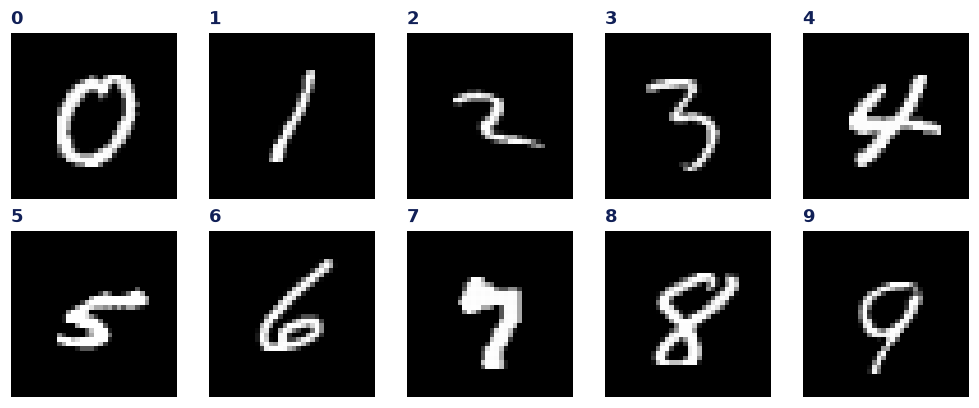

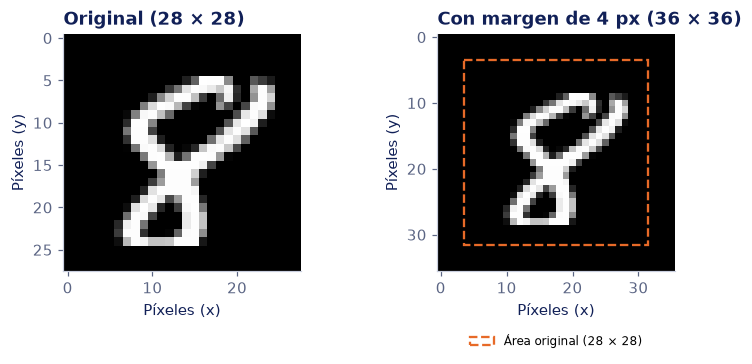

In [3]:
balance = pd.DataFrame({
    "Entrenamiento": pd.Series(y_ent).value_counts().sort_index(),
    "Validación": pd.Series(y_val).value_counts().sort_index(),
    "Prueba": pd.Series(y_prueba).value_counts().sort_index(),
})
balance.index.name = "Dígito"
display(balance)

fig, ejes = plt.subplots(2, 5, figsize=(9, 3.6), layout="constrained")
for digito, ax in enumerate(ejes.flat):
    i = np.flatnonzero(y_ent == digito)[0]
    ax.imshow(X_ent[i, ..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(str(digito))
    ax.axis("off")
plt.show()

# Comparación antes/después del margen en un dígito de ejemplo
from matplotlib.patches import Rectangle

idx_ejemplo = np.flatnonzero(y_ent == 8)[0]
img_original = x_des[i_ent[idx_ejemplo]].astype(np.float32) / 255.0
img_con_margen = X_ent[idx_ejemplo, ..., 0]

fig, ejes = plt.subplots(1, 2, figsize=(6.8, 3.2), layout="constrained")
ejes[0].imshow(img_original, cmap="gray", vmin=0, vmax=1)
ejes[0].set(title="Original (28 × 28)", xlabel="Píxeles (x)", ylabel="Píxeles (y)")
ejes[0].grid(False)

ejes[1].imshow(img_con_margen, cmap="gray", vmin=0, vmax=1)
ejes[1].add_patch(Rectangle(
    (MARGEN - 0.5, MARGEN - 0.5), 28, 28,
    fill=False, edgecolor=NARANJA, linestyle="--", linewidth=1.5,
    label="Área original (28 × 28)",
))
ejes[1].set(title="Con margen de 4 px (36 × 36)", xlabel="Píxeles (x)", ylabel="Píxeles (y)")
ejes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=8)
ejes[1].grid(False)
plt.show()

**Lectura.** Las tres particiones quedaron con dimensiones `36 × 36 × 1` y valores normalizados entre `0.0` y `1.0` en `float32`. El muestreo estratificado mantiene el balance de clases en entrenamiento, validación y prueba: cada dígito representa alrededor del 9 % al 11 % de cada subconjunto, por lo que la exactitud es una métrica adecuada para comparar modelos.

Por curiosidad personal, se agregó la comparación antes/después, donde se aprecia el cambio de escala de `28 × 28` a `36 × 36`, con los 4 píxeles de margen negro añadidos por fuera del recuadro punteado.

Por último, dejamos listas las constantes y funciones auxiliares de entrenamiento tomadas del notebook de clase (`LOTE = 128`, `EPOCAS = 20`, `TASA = 0.001` con Adam). Todas las variantes de esta tarea usarán esta misma configuración.

In [4]:
LOTE = 128
EPOCAS = 20
TASA = 0.001


def lotes(X, y=None, mezclar=False):
    """Crea un Dataset por lotes con mezcla reproducible."""
    datos = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if mezclar:
        datos = datos.shuffle(len(X), seed=SEMILLA)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    return datos.batch(LOTE).with_options(opciones).prefetch(1)


def entrenar(constructor, **configuracion):
    """Entrena un modelo con semilla fija y presupuesto de 20 épocas."""
    keras.utils.set_random_seed(SEMILLA)
    modelo = constructor(**configuracion)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TASA),
        loss="sparse_categorical_crossentropy",
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    historial = modelo.fit(
        lotes(X_ent, y_ent, mezclar=True),
        validation_data=lotes(X_val, y_val),
        epochs=EPOCAS,
        verbose=0,
        shuffle=False,
    ).history
    return modelo, historial


def resumen_modelo(nombre, modelo, historial):
    """Devuelve parámetros entrenables y exactitud de validación en la última época."""
    return {
        "Modelo": nombre,
        "Parámetros entrenables": sum(int(np.prod(v.shape)) for v in modelo.trainable_weights),
        "Exactitud validación (%)": 100 * historial["val_accuracy"][-1],
    }


def curvas(ax, historial, metrica, etiqueta, color, estilo="-"):
    """Grafica la evolución de una métrica por época."""
    valores = historial[metrica]
    ax.plot(range(1, len(valores) + 1), valores, estilo, marker="o", markersize=4,
            label=etiqueta, color=color)

---

# 2. Modelos de referencia

Utilizaremos los dos modelos base del notebook de clase. Ambos comparten el mismo extractor convolucional (dos capas `Conv2D` de 16 filtros `3 × 3` con `padding="same"` y `ReLU`, seguidas de un `MaxPooling2D(2)`) y solo cambian la forma en que pasan esos mapas de `18 × 18 × 16` a la capa de salida `Dense(10)`:

- **CNN + Flatten base:** aplana los mapas a un vector de `5 184` valores antes de la capa densa (`54 330` parámetros entrenables en total).
- **CNN + GAP base:** promedia cada uno de los `16` canales espacialmente a un vector de `16` valores (`2 650` parámetros entrenables en total).

Entrenamos ambos modelos con las mismas particiones y configuración de 20 épocas para verificar la referencia antes de explorar nuevas variantes con GAP.

,Modelo,Parámetros entrenables,Exactitud validación (%),Mapas antes del vector,Longitud del vector,Parámetros capa densa
0,CNN + Flatten base,54330,96.93,18 × 18 × 16,5184,51850
1,CNN + GAP base,2650,44.07,18 × 18 × 16,16,170


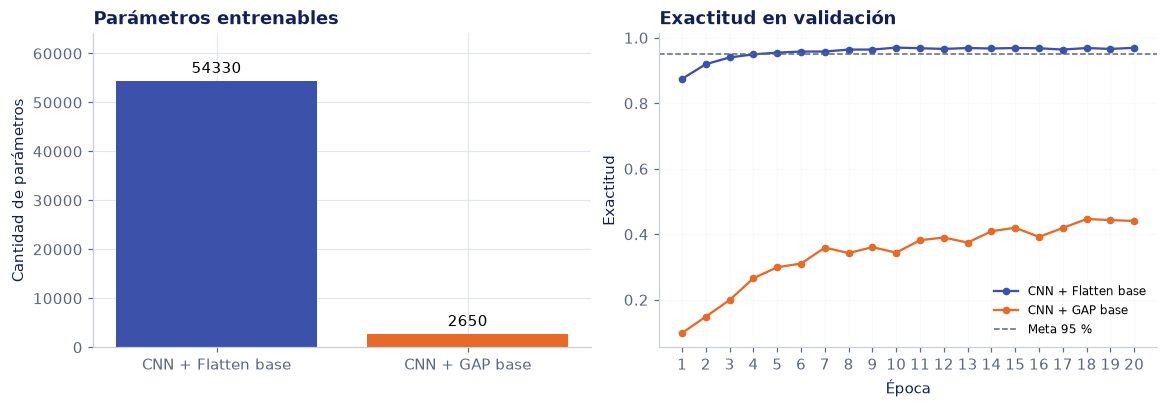

In [5]:
def crear_cnn_base(cabeza="flatten"):
    """Construye la CNN de referencia con cabeza Flatten o GAP."""
    capas = [
        keras.Input(shape=FORMA),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu", name="conv_1"),
        keras.layers.Conv2D(16, 3, padding="same", activation="relu", name="conv_2"),
        keras.layers.MaxPooling2D(2, name="pool"),
    ]
    if cabeza == "flatten":
        capas.append(keras.layers.Flatten(name="vector"))
    elif cabeza == "gap":
        capas.append(keras.layers.GlobalAveragePooling2D(name="vector"))
    else:
        raise ValueError("cabeza debe ser 'flatten' o 'gap'")

    capas.append(keras.layers.Dense(10, activation="softmax", name="salida"))
    return keras.Sequential(capas, name=f"cnn_{cabeza}_base")


def resumen_cnn(nombre, modelo, historial):
    """Agrega información espacial y de la capa de salida al resumen del modelo."""
    fila = resumen_modelo(nombre, modelo, historial)
    forma = modelo.get_layer("vector").input.shape[1:]
    fila["Mapas antes del vector"] = " × ".join(str(d) for d in forma)
    fila["Longitud del vector"] = int(modelo.get_layer("vector").output.shape[-1])
    fila["Parámetros capa densa"] = modelo.get_layer("salida").count_params()
    return fila


modelo_flatten, hist_flatten = entrenar(crear_cnn_base, cabeza="flatten")
modelo_gap_base, hist_gap_base = entrenar(crear_cnn_base, cabeza="gap")

tabla_base = pd.DataFrame([
    resumen_cnn("CNN + Flatten base", modelo_flatten, hist_flatten),
    resumen_cnn("CNN + GAP base", modelo_gap_base, hist_gap_base),
])
display(tabla_base.round(2))

fig, ejes = plt.subplots(1, 2, figsize=(10.5, 3.6), layout="constrained")
barras = ejes[0].bar(
    tabla_base["Modelo"], tabla_base["Parámetros entrenables"], color=[AZUL_MEDIO, NARANJA]
)
ejes[0].bar_label(barras, padding=3, fmt="%d")
ejes[0].set(title="Parámetros entrenables", ylabel="Cantidad de parámetros")
ejes[0].margins(y=0.18)

curvas(ejes[1], hist_flatten, "val_accuracy", "CNN + Flatten base", AZUL_MEDIO)
curvas(ejes[1], hist_gap_base, "val_accuracy", "CNN + GAP base", NARANJA)
ejes[1].axhline(0.95, color=GRIS, linestyle="--", linewidth=1, label="Meta 95 %")
ejes[1].set(title="Exactitud en validación", xlabel="Época", ylabel="Exactitud",
            xticks=range(1, EPOCAS + 1))
ejes[1].legend(fontsize=8)
ejes[1].grid(alpha=0.2)
plt.show()

**Lectura.** Los resultados reproducen lo visto en clase.

- `CNN + Flatten base` alcanza **96.93 %** en validación con **54 330** parámetros (de los cuales 51 850 están en la capa densa final).
- `CNN + GAP base` reduce el tamaño a **2 650** parámetros (170 en la capa densa), pero se queda en **44.07 %** en validación.

La diferencia está en lo que le llega a la capa de salida. Con solo dos convoluciones `3 × 3` antes del pooling, cada canal solo alcanza a ver trazos muy pequeños de la imagen. Cuando GAP promedia todo el mapa en un solo número, se pierde dónde estaban esos trazos y al modelo no le alcanza para distinguir bien los dígitos.

En la siguiente sección probaremos cambios en las capas convolucionales y en el pooling para que cada canal reconozca formas más completas antes de promediar.

---

# 3. Exploración de arquitecturas con GAP

Para que una CNN con GAP supere el 95 % en validación usando menos de 54 330 parámetros, es necesario que las capas convolucionales capturen patrones más amplios del dígito antes de promediar cada canal.

Probaremos **8 variantes** con GAP usando únicamente capas `Conv2D` (`padding="same"`, `ReLU`), `MaxPooling2D(2)`, `GlobalAveragePooling2D` y `Dense(10)`. Todas se entrenan con las mismas particiones, semilla (`42`) y presupuesto de 20 épocas.

El conjunto incluye **cuatro comparaciones donde cambia una sola decisión** respecto a su referencia directa:
1. **Ubicación del pooling:** `V1` (pooling al final) frente a `V2` (pooling intercalado tras cada convolución), ambas con los mismos 4 970 parámetros.
2. **Tamaño de kernel:** `V2` (`3 × 3`) frente a `V3` (`5 × 5`).
3. **Profundidad:** `GAP base` (2 capas) frente a `V1` (3 capas), y `V2` (3 capas) frente a `V4` (4 capas).
4. **Número de filtros:** `V2` (`16-16-16`) frente a `V7` (`16-32-32`) y `V8` (`16-32-64`).

Además incluimos dos variantes compactas (`V5` y `V6`) para explorar si es posible superar el 95 % con alrededor de 5 000 parámetros.

In [6]:
def crear_cnn_gap(filtros, kernel=3, pooling="intercalado", max_pools=3):
    """Construye una CNN con cabeza GAP variando filtros, kernel y ubicación del pooling."""
    capas = [keras.Input(shape=FORMA)]
    pools_usados = 0

    for i, n_filtros in enumerate(filtros):
        capas.append(keras.layers.Conv2D(
            n_filtros, kernel, padding="same", activation="relu", name=f"conv_{i + 1}"
        ))
        if pooling == "intercalado" and pools_usados < max_pools:
            capas.append(keras.layers.MaxPooling2D(2, name=f"pool_{pools_usados + 1}"))
            pools_usados += 1

    if pooling == "final":
        capas.append(keras.layers.MaxPooling2D(2, name="pool"))

    capas.append(keras.layers.GlobalAveragePooling2D(name="vector"))
    capas.append(keras.layers.Dense(10, activation="softmax", name="salida"))
    return keras.Sequential(capas)


variantes_gap = {
    "V1 · 3 capas (pool final)": {
        "desc": "Conv(16,16,16) 3×3 · 1 pool al final",
        "cfg": {"filtros": (16, 16, 16), "kernel": 3, "pooling": "final"},
    },
    "V2 · 3 capas (pool intercalado)": {
        "desc": "Conv(16,16,16) 3×3 · pool tras cada conv",
        "cfg": {"filtros": (16, 16, 16), "kernel": 3, "pooling": "intercalado"},
    },
    "V3 · 3 capas kernel 5×5": {
        "desc": "Conv(16,16,16) 5×5 · pool tras cada conv",
        "cfg": {"filtros": (16, 16, 16), "kernel": 5, "pooling": "intercalado"},
    },
    "V4 · 4 capas (pool intercalado)": {
        "desc": "Conv(16,16,16,16) 3×3 · 3 pools intercalados",
        "cfg": {"filtros": (16, 16, 16, 16), "kernel": 3, "pooling": "intercalado", "max_pools": 3},
    },
    "V5 · Pirámide 8-16-24": {
        "desc": "Conv(8,16,24) 3×3 · pool tras cada conv",
        "cfg": {"filtros": (8, 16, 24), "kernel": 3, "pooling": "intercalado"},
    },
    "V6 · 4 capas 8-12-16-16": {
        "desc": "Conv(8,12,16,16) 3×3 · 3 pools intercalados",
        "cfg": {"filtros": (8, 12, 16, 16), "kernel": 3, "pooling": "intercalado", "max_pools": 3},
    },
    "V7 · Pirámide 16-32-32": {
        "desc": "Conv(16,32,32) 3×3 · pool tras cada conv",
        "cfg": {"filtros": (16, 32, 32), "kernel": 3, "pooling": "intercalado"},
    },
    "V8 · Pirámide 16-32-64": {
        "desc": "Conv(16,32,64) 3×3 · pool tras cada conv",
        "cfg": {"filtros": (16, 32, 64), "kernel": 3, "pooling": "intercalado"},
    },
}

PARAMS_FLATTEN = sum(int(np.prod(v.shape)) for v in modelo_flatten.trainable_weights)

modelos_gap = {"CNN + GAP base": modelo_gap_base}
historiales_gap = {"CNN + GAP base": hist_gap_base}
filas = [{
    "Modelo": "CNN + GAP base",
    "Arquitectura": "Conv(16,16) 3×3 · 1 pool al final",
    **{k: v for k, v in resumen_cnn("CNN + GAP base", modelo_gap_base, hist_gap_base).items()
       if k in ("Mapas antes del vector", "Parámetros entrenables", "Exactitud validación (%)")},
}]

for nombre, info in variantes_gap.items():
    modelo, historial = entrenar(crear_cnn_gap, **info["cfg"])
    modelos_gap[nombre] = modelo
    historiales_gap[nombre] = historial
    res = resumen_cnn(nombre, modelo, historial)
    filas.append({
        "Modelo": nombre,
        "Arquitectura": info["desc"],
        "Mapas antes del vector": res["Mapas antes del vector"],
        "Parámetros entrenables": res["Parámetros entrenables"],
        "Exactitud validación (%)": res["Exactitud validación (%)"],
    })

tabla_gap = pd.DataFrame(filas)
tabla_gap["Cumple (>95% y <Flatten)"] = (
    (tabla_gap["Exactitud validación (%)"] > 95.0)
    & (tabla_gap["Parámetros entrenables"] < PARAMS_FLATTEN)
)
tabla_gap["Ahorro vs Flatten (%)"] = (
    100 * (1 - tabla_gap["Parámetros entrenables"] / PARAMS_FLATTEN)
)

display(tabla_gap.round(2))

validas = tabla_gap[tabla_gap["Cumple (>95% y <Flatten)"]].sort_values("Parámetros entrenables")
seleccion = validas.iloc[0]
nombre_seleccionado = seleccion["Modelo"]
modelo_gap_seleccionado = modelos_gap[nombre_seleccionado]
hist_gap_seleccionado = historiales_gap[nombre_seleccionado]

ahorro_abs = PARAMS_FLATTEN - int(seleccion["Parámetros entrenables"])
ahorro_pct = 100 * ahorro_abs / PARAMS_FLATTEN
print(
    f"GAP seleccionado: {nombre_seleccionado} | "
    f"Parámetros: {int(seleccion['Parámetros entrenables']):,} | "
    f"Validación: {seleccion['Exactitud validación (%)']:.2f} % | "
    f"Ahorro vs Flatten: {ahorro_abs:,} parámetros ({ahorro_pct:.2f} %)"
)

,Modelo,Arquitectura,Parámetros entrenables,Exactitud validación (%),Mapas antes del vector,Cumple (>95% y <Flatten),Ahorro vs Flatten (%)
0,CNN + GAP base,"Conv(16,16) 3×3 · 1 pool al final",2650,44.07,18 × 18 × 16,False,95.12
1,V1 · 3 capas (pool final),"Conv(16,16,16) 3×3 · 1 pool al final",4970,53.07,18 × 18 × 16,False,90.85
2,V2 · 3 capas (pool intercalado),"Conv(16,16,16) 3×3 · pool tras cada conv",4970,90.40,4 × 4 × 16,False,90.85
3,V3 · 3 capas kernel 5×5,"Conv(16,16,16) 5×5 · pool tras cada conv",13418,94.40,4 × 4 × 16,False,75.30
4,V4 · 4 capas (pool intercalado),"Conv(16,16,16,16) 3×3 · 3 pools intercalados",7290,94.00,4 × 4 × 16,False,86.58
5,V5 · Pirámide 8-16-24,"Conv(8,16,24) 3×3 · pool tras cada conv",4978,93.07,4 × 4 × 24,False,90.84
6,V6 · 4 capas 8-12-16-16,"Conv(8,12,16,16) 3×3 · 3 pools intercalados",5190,93.53,4 × 4 × 16,False,90.45
7,V7 · Pirámide 16-32-32,"Conv(16,32,32) 3×3 · pool tras cada conv",14378,93.47,4 × 4 × 32,False,73.54
8,V8 · Pirámide 16-32-64,"Conv(16,32,64) 3×3 · pool tras cada conv",23946,95.40,4 × 4 × 64,True,55.92


GAP seleccionado: V8 · Pirámide 16-32-64 | Parámetros: 23,946 | Validación: 95.40 % | Ahorro vs Flatten: 30,384 parámetros (55.92 %)


**Lectura.** Las ocho variantes mejoran respecto al GAP base (`44.07%`), pero en esta primera ronda solo `V8 · Pirámide 16-32-64` supera el 95% en validación, llegando a **95.40%** con **23 946** parámetros (es decir, **55.92% menos** que `Flatten base`). En las gráficas siguientes vemos con más claridad qué cambio aportó más y cómo se relaciona el tamaño de cada modelo con su desempeño.

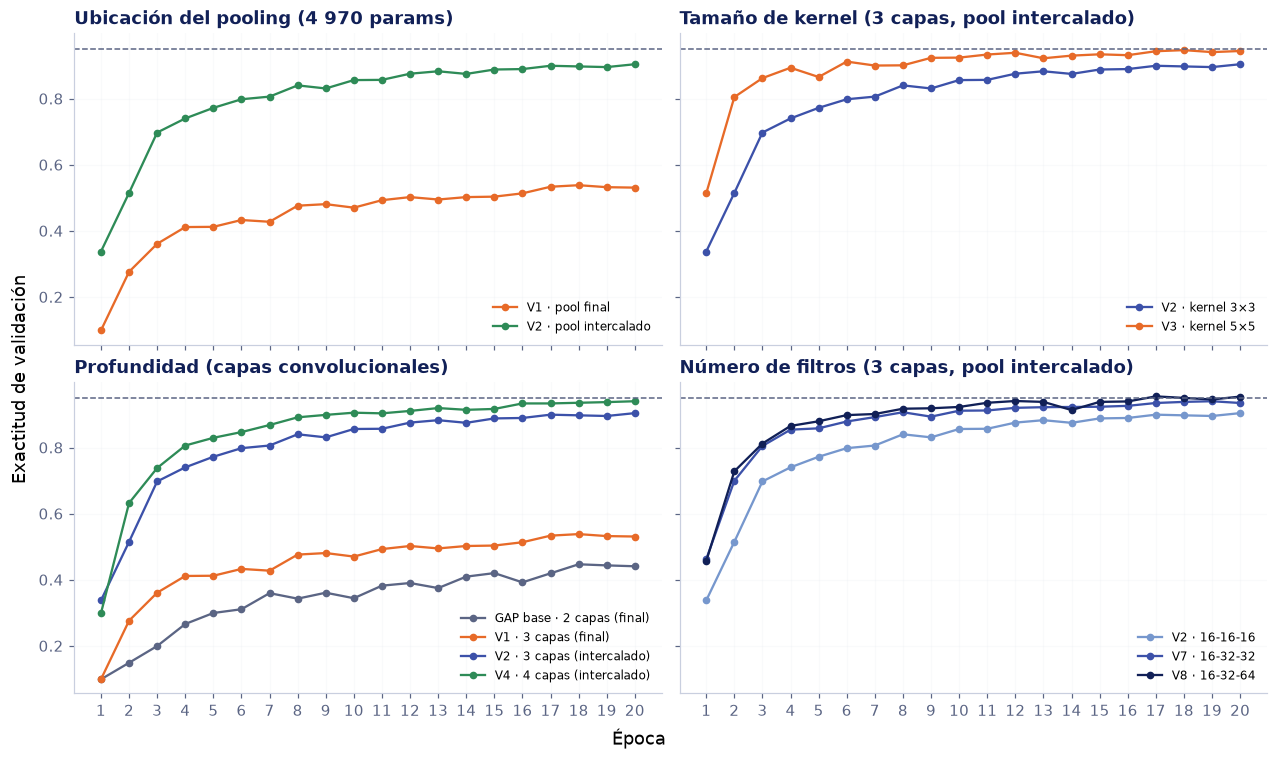

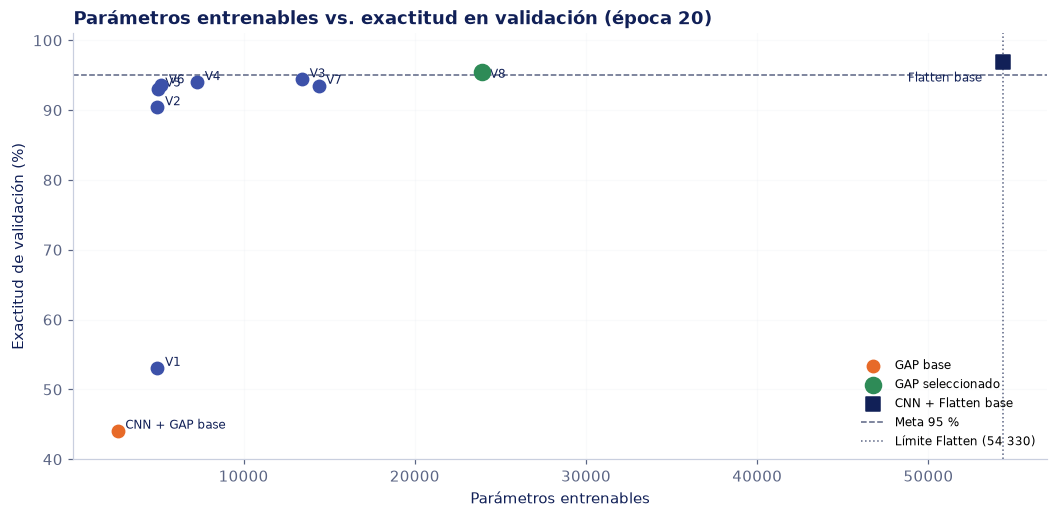

In [7]:
# 1) Comparaciones controladas de una sola decisión
comparaciones = [
    ("Ubicación del pooling (4 970 params)", [
        ("V1 · pool final", "V1 · 3 capas (pool final)", NARANJA),
        ("V2 · pool intercalado", "V2 · 3 capas (pool intercalado)", VERDE),
    ]),
    ("Tamaño de kernel (3 capas, pool intercalado)", [
        ("V2 · kernel 3×3", "V2 · 3 capas (pool intercalado)", AZUL_MEDIO),
        ("V3 · kernel 5×5", "V3 · 3 capas kernel 5×5", NARANJA),
    ]),
    ("Profundidad (capas convolucionales)", [
        ("GAP base · 2 capas (final)", "CNN + GAP base", GRIS),
        ("V1 · 3 capas (final)", "V1 · 3 capas (pool final)", NARANJA),
        ("V2 · 3 capas (intercalado)", "V2 · 3 capas (pool intercalado)", AZUL_MEDIO),
        ("V4 · 4 capas (intercalado)", "V4 · 4 capas (pool intercalado)", VERDE),
    ]),
    ("Número de filtros (3 capas, pool intercalado)", [
        ("V2 · 16-16-16", "V2 · 3 capas (pool intercalado)", AZUL),
        ("V7 · 16-32-32", "V7 · Pirámide 16-32-32", AZUL_MEDIO),
        ("V8 · 16-32-64", "V8 · Pirámide 16-32-64", AZUL_OSCURO),
    ]),
]

fig, ejes = plt.subplots(2, 2, figsize=(11.5, 6.8), sharex=True, sharey=True, layout="constrained")
for ax, (titulo, series) in zip(ejes.flat, comparaciones):
    for etiqueta, clave, color in series:
        curvas(ax, historiales_gap[clave], "val_accuracy", etiqueta, color)
    ax.axhline(0.95, color=GRIS, linestyle="--", linewidth=1)
    ax.set(title=titulo, xticks=range(1, EPOCAS + 1))
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(alpha=0.2)

fig.supxlabel("Época")
fig.supylabel("Exactitud de validación")
plt.show()

# 2) Parámetros entrenables vs. exactitud en validación
fig, ax = plt.subplots(figsize=(9.5, 4.6), layout="constrained")

for _, fila in tabla_gap.iterrows():
    es_sel = fila["Modelo"] == nombre_seleccionado
    es_base = fila["Modelo"] == "CNN + GAP base"
    color = VERDE if es_sel else (NARANJA if es_base else AZUL_MEDIO)
    tam = 110 if es_sel else 65
    etiqueta_leyenda = (
        "GAP seleccionado" if es_sel
        else ("GAP base" if es_base else None)
    )
    ax.scatter(
        fila["Parámetros entrenables"], fila["Exactitud validación (%)"],
        color=color, s=tam, zorder=4, label=etiqueta_leyenda,
    )
    nombre_corto = fila["Modelo"].split(" · ")[0]
    offset_y = 1.4 if not es_sel else -3.5
    ax.annotate(
        nombre_corto,
        (fila["Parámetros entrenables"], fila["Exactitud validación (%)"]),
        textcoords="offset points", xytext=(5, offset_y), fontsize=8, color=AZUL_OSCURO,
    )

acc_flatten_val = 100 * hist_flatten["val_accuracy"][-1]
ax.scatter(PARAMS_FLATTEN, acc_flatten_val, color=AZUL_OSCURO, marker="s", s=85, zorder=4,
           label="CNN + Flatten base")
ax.annotate("Flatten base", (PARAMS_FLATTEN, acc_flatten_val),
            textcoords="offset points", xytext=(-62, -13), fontsize=8, color=AZUL_OSCURO)

ax.axhline(95.0, color=GRIS, linestyle="--", linewidth=1, label="Meta 95 %")
ax.axvline(PARAMS_FLATTEN, color=GRIS, linestyle=":", linewidth=1, label="Límite Flatten (54 330)")
ax.set(
    title="Parámetros entrenables vs. exactitud en validación (época 20)",
    xlabel="Parámetros entrenables",
    ylabel="Exactitud de validación (%)",
    ylim=(40, 101),
)
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.2)
plt.show()

**Lectura.** El cambio que más diferencia hizo respecto al GAP base (`44.07 %`) fue dónde colocamos el pooling. Al comparar `V1` y `V2` (que tienen los mismos **4 970 parámetros**), pasar de un solo pooling al final a intercalar uno después de cada convolución subió la exactitud en validación de **53.07 %** a **90.40 %**.

Al ir reduciendo el tamaño de los mapas paso a paso (hasta llegar a `4 × 4`), las capas siguientes alcanzan a ver una porción más amplia del dígito antes de que GAP promedie cada canal.

Sobre esa base de pooling intercalado, los demás ajustes aportaron mejoras más moderadas. Agregar una cuarta capa convolucional (`V4`) subió la exactitud a **94.00%** con 7 290 parámetros, mientras que cambiar los kernels de `3 × 3` a `5 × 5` (`V3`) llegó a **94.40%**, aunque casi triplica el tamaño del modelo (13 418 parámetros). En cambio, agregar una capa dejando el pooling al final (`GAP base` frente a `V1`) solo subió de 44.07% a 53.07%.

El último paso para cruzar la meta fue aumentar los filtros conforme avanza la red (`V2`, `V7` y `V8`), ya que en una CNN con GAP los filtros de la última capa son los valores que llegan a la salida. Pasar de 16 a 32 y finalmente a 64 filtros llevó la validación de 90.40% a 93.47% y a **95.40%** con `V8` (23 946 parámetros).

## 3.1. Búsqueda de una arquitectura más compacta

Al revisar la tabla anterior surge la cuestión, `V8` ya superó el 95 % en validación, pero requirió  de **23 946** parámetros, mientras que `V4` (4 capas con 16 filtros y 3 poolings intercalados) llegó a **94.00%** con solo **7 290** parámetros.

Como estamos buscando elegir la variante con menos parámetros entre las que superen el 95 % en validación, se plantea probar tres configuraciones adicionales de 4 capas con un aumento moderado de filtros hacia el final (`V9`, `V10` y `V11`, entre ~8 500 y ~13 200 parámetros) para verificar si es posible pasar del 95% usando menos de la mitad de los parámetros de `V8`.

In [8]:
variantes_extra = {
    "V9 · 4 capas 8-16-16-32": {
        "desc": "Conv(8,16,16,32) 3×3 · 3 pools intercalados",
        "cfg": {"filtros": (8, 16, 16, 32), "kernel": 3, "pooling": "intercalado", "max_pools": 3},
    },
    "V10 · 4 capas 8-16-24-32": {
        "desc": "Conv(8,16,24,32) 3×3 · 3 pools intercalados",
        "cfg": {"filtros": (8, 16, 24, 32), "kernel": 3, "pooling": "intercalado", "max_pools": 3},
    },
    "V11 · 4 capas 16-16-24-32": {
        "desc": "Conv(16,16,24,32) 3×3 · 3 pools intercalados",
        "cfg": {"filtros": (16, 16, 24, 32), "kernel": 3, "pooling": "intercalado", "max_pools": 3},
    },
}

filas_extra = []
for nombre, info in variantes_extra.items():
    modelo, historial = entrenar(crear_cnn_gap, **info["cfg"])
    modelos_gap[nombre] = modelo
    historiales_gap[nombre] = historial
    res = resumen_cnn(nombre, modelo, historial)
    filas_extra.append({
        "Modelo": nombre,
        "Arquitectura": info["desc"],
        "Mapas antes del vector": res["Mapas antes del vector"],
        "Parámetros entrenables": res["Parámetros entrenables"],
        "Exactitud validación (%)": res["Exactitud validación (%)"],
    })

tabla_extra = pd.DataFrame(filas_extra)
tabla_extra["Cumple (>95% y <Flatten)"] = (
    (tabla_extra["Exactitud validación (%)"] > 95.0)
    & (tabla_extra["Parámetros entrenables"] < PARAMS_FLATTEN)
)
tabla_extra["Ahorro vs Flatten (%)"] = (
    100 * (1 - tabla_extra["Parámetros entrenables"] / PARAMS_FLATTEN)
)

tabla_completa = pd.concat([tabla_gap, tabla_extra], ignore_index=True)
display(tabla_extra.round(2))

# Actualizar la selección (todas las variantes)
validas = tabla_completa[tabla_completa["Cumple (>95% y <Flatten)"]].sort_values("Parámetros entrenables")
display(validas[["Modelo", "Parámetros entrenables", "Exactitud validación (%)", "Ahorro vs Flatten (%)"]].round(2))

seleccion = validas.iloc[0]
nombre_seleccionado = seleccion["Modelo"]
modelo_gap_seleccionado = modelos_gap[nombre_seleccionado]
hist_gap_seleccionado = historiales_gap[nombre_seleccionado]

ahorro_abs = PARAMS_FLATTEN - int(seleccion["Parámetros entrenables"])
ahorro_pct = 100 * ahorro_abs / PARAMS_FLATTEN
print(
    f"GAP seleccionado final: {nombre_seleccionado} | "
    f"Parámetros: {int(seleccion['Parámetros entrenables']):,} | "
    f"Validación: {seleccion['Exactitud validación (%)']:.2f} % | "
    f"Ahorro vs Flatten: {ahorro_abs:,} parámetros ({ahorro_pct:.2f} %)"
)

,Modelo,Arquitectura,Mapas antes del vector,Parámetros entrenables,Exactitud validación (%),Cumple (>95% y <Flatten),Ahorro vs Flatten (%)
0,V9 · 4 capas 8-16-16-32,"Conv(8,16,16,32) 3×3 · 3 pools intercalados",4 × 4 × 32,8538,94.33,False,84.28
1,V10 · 4 capas 8-16-24-32,"Conv(8,16,24,32) 3×3 · 3 pools intercalados",4 × 4 × 32,12002,94.33,False,77.91
2,V11 · 4 capas 16-16-24-32,"Conv(16,16,24,32) 3×3 · 3 pools intercalados",4 × 4 × 32,13234,94.27,False,75.64


,Modelo,Parámetros entrenables,Exactitud validación (%),Ahorro vs Flatten (%)
8,V8 · Pirámide 16-32-64,23946,95.4,55.92


GAP seleccionado final: V8 · Pirámide 16-32-64 | Parámetros: 23,946 | Validación: 95.40 % | Ahorro vs Flatten: 30,384 parámetros (55.92 %)


**Lectura.** Las tres variantes de 4 capas (`V9`, `V10` y `V11`) mejoran un poco sobre `V4` (`94.00%`), pero todas se estancan alrededor de **94.3 %** sin llegar al 95 %.

Al comparar estas pruebas con `V7` (`93.47%`) y `V8` (`95.40%`), se nota un patrón: todos los modelos que terminan en **32 canales** quedan cerca de 94 %, mientras que al subir a **64 canales** antes de GAP (`V8`), GAP le entrega más información a la salida para distinguir los 10 dígitos. Por ahora, **V8 · Pirámide 16-32-64** sigue siendo la arquitectura seleccionada.

Sin embargo, a partir de esta observación podemos probar una última hipótesis: mantener **64 canales en la última capa** antes de GAP, pero reducir el número de filtros en las primeras capas (`V12: 8-16-64` con 3 capas y `V13: 8-16-16-64` con 4 capas). Así verificamos si el cuello de botella estaba en el tamaño del vector que llega a GAP y si es posible superar el 95% con menos de la mitad de los parámetros de `V8`.

In [9]:
variantes_64 = {
    "V12 · 3 capas 8-16-64": {
        "desc": "Conv(8,16,64) 3×3 · pool tras cada conv",
        "cfg": {"filtros": (8, 16, 64), "kernel": 3, "pooling": "intercalado"},
    },
    "V13 · 4 capas 8-16-16-64": {
        "desc": "Conv(8,16,16,64) 3×3 · 3 pools intercalados",
        "cfg": {"filtros": (8, 16, 16, 64), "kernel": 3, "pooling": "intercalado", "max_pools": 3},
    },
}

filas_64 = []
for nombre, info in variantes_64.items():
    modelo, historial = entrenar(crear_cnn_gap, **info["cfg"])
    modelos_gap[nombre] = modelo
    historiales_gap[nombre] = historial
    res = resumen_cnn(nombre, modelo, historial)
    filas_64.append({
        "Modelo": nombre,
        "Arquitectura": info["desc"],
        "Mapas antes del vector": res["Mapas antes del vector"],
        "Parámetros entrenables": res["Parámetros entrenables"],
        "Exactitud validación (%)": res["Exactitud validación (%)"],
    })

tabla_64 = pd.DataFrame(filas_64)
tabla_64["Cumple (>95% y <Flatten)"] = (
    (tabla_64["Exactitud validación (%)"] > 95.0)
    & (tabla_64["Parámetros entrenables"] < PARAMS_FLATTEN)
)
tabla_64["Ahorro vs Flatten (%)"] = (
    100 * (1 - tabla_64["Parámetros entrenables"] / PARAMS_FLATTEN)
)

tabla_completa = pd.concat([tabla_completa, tabla_64], ignore_index=True)
display(tabla_64.round(2))

validas = tabla_completa[tabla_completa["Cumple (>95% y <Flatten)"]].sort_values("Parámetros entrenables")
print("Variantes que cumplen ambos requisitos (>95 % en validación y <54 330 parámetros):")
display(validas[["Modelo", "Arquitectura", "Parámetros entrenables", "Exactitud validación (%)", "Ahorro vs Flatten (%)"]].round(2))

seleccion = validas.iloc[0]
nombre_seleccionado = seleccion["Modelo"]
modelo_gap_seleccionado = modelos_gap[nombre_seleccionado]
hist_gap_seleccionado = historiales_gap[nombre_seleccionado]

ahorro_abs = PARAMS_FLATTEN - int(seleccion["Parámetros entrenables"])
ahorro_pct = 100 * ahorro_abs / PARAMS_FLATTEN
print(
    f"GAP seleccionado final: {nombre_seleccionado} | "
    f"Parámetros: {int(seleccion['Parámetros entrenables']):,} | "
    f"Validación: {seleccion['Exactitud validación (%)']:.2f} % | "
    f"Ahorro vs Flatten: {ahorro_abs:,} parámetros ({ahorro_pct:.2f} %)"
)

,Modelo,Arquitectura,Mapas antes del vector,Parámetros entrenables,Exactitud validación (%),Cumple (>95% y <Flatten),Ahorro vs Flatten (%)
0,V12 · 3 capas 8-16-64,"Conv(8,16,64) 3×3 · pool tras cada conv",4 × 4 × 64,11178,94.8,False,79.43
1,V13 · 4 capas 8-16-16-64,"Conv(8,16,16,64) 3×3 · 3 pools intercalados",4 × 4 × 64,13498,94.4,False,75.16


Variantes que cumplen ambos requisitos (>95 % en validación y <54 330 parámetros):


,Modelo,Arquitectura,Parámetros entrenables,Exactitud validación (%),Ahorro vs Flatten (%)
8,V8 · Pirámide 16-32-64,"Conv(16,32,64) 3×3 · pool tras cada conv",23946,95.4,55.92


GAP seleccionado final: V8 · Pirámide 16-32-64 | Parámetros: 23,946 | Validación: 95.40 % | Ahorro vs Flatten: 30,384 parámetros (55.92 %)


**Lectura.** La hipótesis iba bien encaminada: `V12` (`8-16-64`) subió a **94.80%** con solo **11 178** parámetros, quedándose a tres imágenes de la meta, mientras que `V13` (`8-16-16-64`) llegó a **94.40%**. Esto confirma que llevar 64 canales a GAP ayuda a separar mejor los dígitos, aunque reducir demasiado los filtros en las primeras capas (`8` y `16` en vez de `16` y `32`) todavía limita un poco la exactitud en 20 épocas.

Por tanto, cerramos la exploración en validación seleccionando **V8 · Pirámide 16-32-64** (`23 946` parámetros entrenables y **95.40%** en validación), que cumple los requisitos y ahorra **30 384 parámetros** (**55.92%**) respecto a `CNN + Flatten base`.

---

# 4. Evaluación del efecto del desplazamiento

Ahora usamos por primera vez el conjunto de prueba (`X_prueba`, 2 000 imágenes) para comparar **CNN + Flatten base**, **CNN + GAP base** y nuestro **GAP seleccionado (`V8 · Pirámide 16-32-64`)** sin reentrenar ninguno de los tres modelos.

Reutilizamos la función `desplazar` del notebook de clase para mover cada dígito **0, 2 y 4 píxeles** dentro del margen negro. Para 2 y 4 píxeles promediamos la exactitud obtenida en las cuatro direcciones (derecha, izquierda, abajo y arriba), y calculamos la caída en puntos porcentuales como `Acc(0 px) - Acc(4 px)`.

,0 px (%),2 px (%),4 px (%),Caída a 4 px (pp)
Modelo,,,,
CNN + Flatten base,97.10,82.79,37.30,59.80
CNN + GAP base,46.45,46.46,46.46,-0.01
GAP seleccionado (V8),96.15,87.95,72.51,23.64


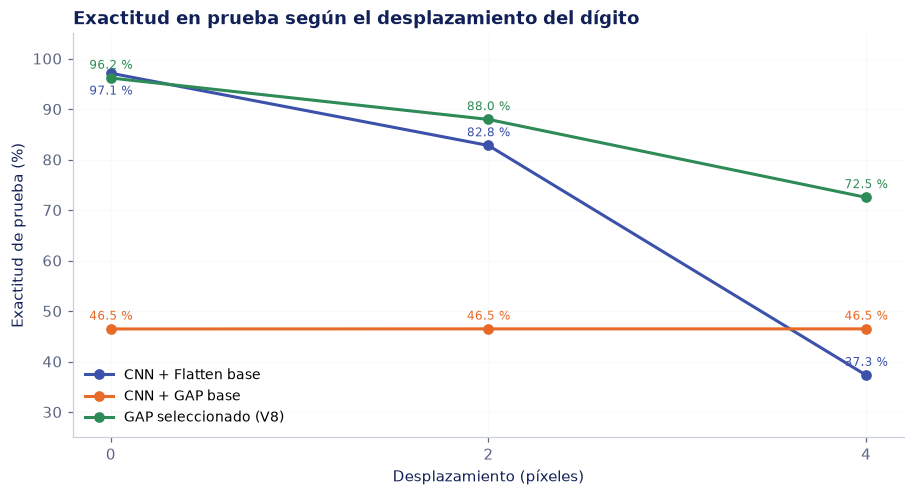

In [10]:
def desplazar(imagenes, dy, dx):
    """Desplaza un lote de imágenes dy píxeles en vertical y dx en horizontal."""
    if max(abs(dy), abs(dx)) > MARGEN:
        raise ValueError("Usa un desplazamiento dentro del margen de la imagen.")
    alto, ancho = imagenes.shape[1:3]
    resultado = np.zeros_like(imagenes)
    origen_y = slice(max(-dy, 0), alto - max(dy, 0))
    origen_x = slice(max(-dx, 0), ancho - max(dx, 0))
    destino_y = slice(max(dy, 0), alto - max(-dy, 0))
    destino_x = slice(max(dx, 0), ancho - max(-dx, 0))
    resultado[:, destino_y, destino_x, :] = imagenes[:, origen_y, origen_x, :]
    return resultado


def predecir(modelo, imagenes):
    """Devuelve la clase predicha para cada imagen del lote."""
    return modelo.predict(lotes(imagenes), verbose=0).argmax(axis=1)


modelos_eval = {
    "CNN + Flatten base": modelo_flatten,
    "CNN + GAP base": modelo_gap_base,
    f"GAP seleccionado ({nombre_seleccionado.split(' · ')[0]})": modelo_gap_seleccionado,
}
distancias = (0, 2, 4)

pred_originales = {nombre: predecir(modelo, X_prueba) for nombre, modelo in modelos_eval.items()}
exactitudes = {
    nombre: [100 * np.mean(pred == y_prueba)]
    for nombre, pred in pred_originales.items()
}

pred_derecha = {}
for distancia in distancias[1:]:
    resultados_dir = {nombre: [] for nombre in modelos_eval}
    direcciones = ((0, distancia), (0, -distancia), (distancia, 0), (-distancia, 0))
    for dy, dx in direcciones:
        imagenes = desplazar(X_prueba, dy, dx)
        for nombre, modelo in modelos_eval.items():
            pred = predecir(modelo, imagenes)
            resultados_dir[nombre].append(100 * np.mean(pred == y_prueba))
            if dy == 0 and dx == MARGEN:
                pred_derecha[nombre] = pred
    for nombre, valores in resultados_dir.items():
        exactitudes[nombre].append(float(np.mean(valores)))

tabla_desp = pd.DataFrame.from_dict(
    exactitudes, orient="index", columns=[f"{d} px (%)" for d in distancias]
)
tabla_desp["Caída a 4 px (pp)"] = tabla_desp["0 px (%)"] - tabla_desp["4 px (%)"]
tabla_desp.index.name = "Modelo"
display(tabla_desp.round(2))

fig, ax = plt.subplots(figsize=(8.2, 4.4), layout="constrained")
colores_eval = [AZUL_MEDIO, NARANJA, VERDE]
for (nombre, valores), color in zip(exactitudes.items(), colores_eval):
    ax.plot(distancias, valores, marker="o", linewidth=2, label=nombre, color=color)
    for d, v in zip(distancias, valores):
        despl_y = 6 if "Flatten" not in nombre or d != 0 else -14
        ax.annotate(f"{v:.1f} %", (d, v), textcoords="offset points",
                    xytext=(0, despl_y), ha="center", fontsize=8, color=color)

ax.set(
    title="Exactitud en prueba según el desplazamiento del dígito",
    xlabel="Desplazamiento (píxeles)",
    ylabel="Exactitud de prueba (%)",
    xticks=distancias,
    ylim=(25, 105),
)
ax.legend(fontsize=9, loc="lower left")
ax.grid(alpha=0.2)
plt.show()

**Lectura.** En las imágenes originales (`0 px`), `CNN + Flatten base` (`97.10%`) y `GAP seleccionado (V8)` (`96.15%`) parten a menos de un punto porcentual de distancia, mientras que `CNN + GAP base` se queda en `46.45%`.

Al mover los dígitos, el comportamiento cambia desde los **2 píxeles**: `V8` supera a `Flatten base` por más de cinco puntos (`87.95%` vs. `82.79 %`).

A **4 píxeles**, la diferencia se nota más: `Flatten base` cae **59.80 pp** y baja hasta **37.30%**, porque su capa densa aprendió pesos ligados a coordenadas fijas de la imagen. Por contraparte, `V8` cae **23.64 pp** y conserva **72.51%** de exactitud, casi el doble que `Flatten base`.

Comparado con `CNN + GAP base`, este último prácticamente no cae, pero ese dato por sí solo sería engañoso si no se mira su nivel de exactitud, ya que se mantiene plano en `46.46%`. Aunque `V8` sí pierde exactitud al desplazar (porque intercalar tres `MaxPooling2D(2)` hace que la alineación de las ventanas cambie al mover el dígito), conserva **72.51%** a 4 píxeles, superando por 26 puntos a `GAP base` y por 35 puntos a `Flatten base`.

Para ver este efecto directamente sobre los dígitos, mostramos cuatro ejemplos de prueba donde `CNN + Flatten base` acierta en la imagen original y falla al moverla 4 píxeles a la derecha, mientras que `V8` conserva el acierto.

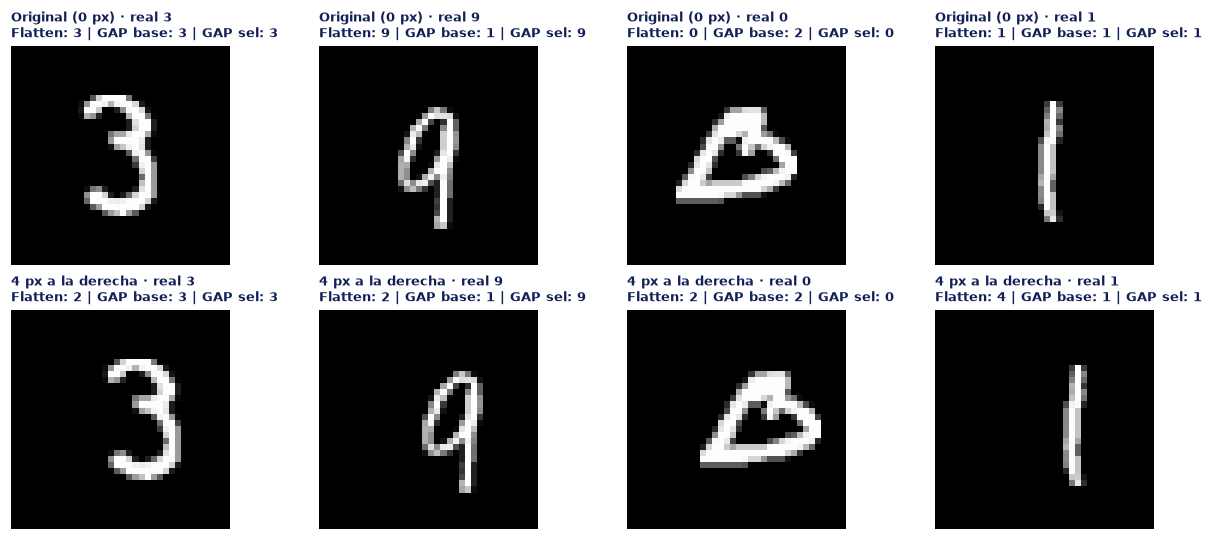

In [11]:
# Ejemplos donde CNN + Flatten acierta en el dígito original y falla al moverlo 4 px a la derecha
clave_sel = f"GAP seleccionado ({nombre_seleccionado.split(' · ')[0]})"
falla_flatten = (
    (pred_originales["CNN + Flatten base"] == y_prueba)
    & (pred_derecha["CNN + Flatten base"] != y_prueba)
    & (pred_derecha[clave_sel] == y_prueba)
)
indices = np.flatnonzero(falla_flatten)[:4]
if len(indices) < 4:
    indices = np.arange(4)

fig, ejes = plt.subplots(2, len(indices), figsize=(2.8 * len(indices), 4.8),
                         squeeze=False, layout="constrained")
for col, i in enumerate(indices):
    par = (X_prueba[i, ..., 0], desplazar(X_prueba[i:i + 1], 0, MARGEN)[0, ..., 0])
    for fila, (etiqueta, pred) in enumerate([
        ("Original (0 px)", pred_originales),
        ("4 px a la derecha", pred_derecha),
    ]):
        ax = ejes[fila, col]
        ax.imshow(par[fila], cmap="gray", vmin=0, vmax=1)
        ax.set_title(
            f"{etiqueta} · real {y_prueba[i]}\n"
            f"Flatten: {pred['CNN + Flatten base'][i]} | "
            f"GAP base: {pred['CNN + GAP base'][i]} | "
            f"GAP sel: {pred[clave_sel][i]}",
            fontsize=8.5,
        )
        ax.axis("off")
plt.show()

**Lectura.** En los cuatro casos el dígito sigue siendo completamente legible tras moverse 4 píxeles a la derecha dentro del margen negro, pero ese corrimiento basta para que `CNN + Flatten base` cambie su predicción y falle. `GAP seleccionado (V8)` mantiene la clase correcta en todos ellos, mientras que `GAP base` ya mostraba errores incluso en algunos dígitos sin desplazar.

---

# 5. Conclusiones

1. **¿Cuál fue el cambio más importante para que GAP superara el 95 % en validación?**  
   El cambio más importante fue poner una capa de pooling después de cada convolución, en vez de dejar una sola al final. Con exactamente los mismos `4 970` parámetros, eso hizo que la exactitud en validación subiera de `53.07%` (`V1`) a `90.40%` (`V2`). Al ir reduciendo la imagen paso a paso, las últimas capas alcanzan a ver partes más grandes del dígito antes de que GAP promedie cada canal. Con esa estructura, aumentar los filtros hasta llegar a 64 en la última capa (`V8: 16-32-64`) fue lo que permitió cruzar el umbral con **95.40%**.

2. **¿Cuántos parámetros ahorraste frente a Flatten?**  
   La variante seleccionada (**V8 · Pirámide 16-32-64**) tiene **23 946 parámetros entrenables**, frente a los **54 330** de `CNN + Flatten base`. Esto representa un ahorro de **30 384 parámetros**, es decir, **55.92 % menos**.

3. **¿Tu GAP seleccionado reconoce mejor los dígitos desplazados que Flatten? ¿A partir de qué distancia se aprecia la diferencia?**  
   Sí. Aunque en las imágenes sin mover `Flatten` empieza un poco más arriba (`97.10 %` contra `96.15 %`), la ventaja de `V8` ya se nota desde los **2 píxeles** (`87.95 %` frente a `82.79 %`).
   
   A **4 píxeles** la diferencia es mucho mayor: `Flatten` cae hasta `37.30 %`, mientras que `V8` conserva **72.51 %**, casi el doble.

---
### Declaración sobre el uso de IA Generativa

Este notebook fue elaborado con apoyo de modelos de lenguaje basados en IA (Gemini / Antigravity) como herramientas de apoyo para la depuración de código, revisión de textos y formato markdown. El razonamiento analítico, el planteamiento metodológico, la interpretación de resultados y la redacción final de los hallazgos son responsabilidad del autor.